In [4]:
import numpy as np, bruce, matplotlib.pyplot as plt, glob, os, gc
from astropy.table import Table, hstack
from astropy.io import fits
from scipy.signal import find_peaks

# Load the monos

In [5]:
monos = Table.read('monos.csv', format='csv')
print(monos.colnames)

['TIC ID', 'Linked TIC ID', 'TOI ID', 'DR2 ID', 'Vmag', 'Tmag', 'Mass [Msol]', 'Radius [Rsun]', 'Teff [K]', 'RA [deg]', 'Dec [deg]', 'DR3 RUWE', 'DR3 RVamp [km/s]', 'Star type', 'Archive', '[sunset] -->  Airmass -->  [sunrise]', 'DSS red (NGTS 3-pix aperture)', 'Sector of transit', 'Upcoming TESS sectors', 'TESS review date', 't_zero [BJD]', 'FItted Period [day]', 'radius_1 (R1/a)', 'k=R2/R1', 'Impact parameter', 'R2 [Rjup]', 'Width [hour]', 'Depth [normalised flux]', 'Scheduled NGTS', 'Review date', 'Action', 'Priority', 'TESS', 'NGTS', 'CORALIE', 'HARPS', 'FEROS', 'Other RV']


[]
[]
['/Volumes/NGTS/TIC-21725734_REF_IMAGE_80120251029041511_PHOT.fits', '/Volumes/NGTS/TIC-21725734_REF_IMAGE_80320240903070727_PHOT.fits', '/Volumes/NGTS/TIC-21725734_REF_IMAGE_80820230728093544_PHOT.fits', '/Volumes/NGTS/TIC-21725734_REF_IMAGE_80820230915062604_PHOT.fits']


/Users/sam/anaconda3/lib/python3.9/site-packages/numpy/core/fromnumeric.py:771: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)


[]
[]
[]
[]
[]
[]
[]
[]
[]
['/Volumes/NGTS/TIC-86433395_REF_IMAGE_80420250204072020_PHOT.fits']
[]
[]
[]
[]
[]
['/Volumes/NGTS/TIC-106056929_REF_IMAGE_80320250115051334_PHOT.fits', '/Volumes/NGTS/TIC-106056929_REF_IMAGE_81120241104081032_PHOT.fits']
No peaks.
['/Volumes/NGTS/TIC-117843726_REF_IMAGE_80320230728084321_PHOT.fits', '/Volumes/NGTS/TIC-117843726_REF_IMAGE_80320230915053052_PHOT.fits', '/Volumes/NGTS/TIC-117843726_REF_IMAGE_80720240905070703_PHOT.fits']
No peaks.
No peaks.
No peaks.
[]
['/Volumes/NGTS/TIC-123570723_REF_IMAGE_80220250914073058_PHOT.fits', '/Volumes/NGTS/TIC-123570723_REF_IMAGE_80720230826075913_PHOT.fits', '/Volumes/NGTS/TIC-123570723_REF_IMAGE_80720230915064052_PHOT.fits']


/var/folders/fs/c4gpqhmx5tbcbsv_cbs0yhn80000gn/T/ipykernel_35129/363412398.py:64: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig1, ax1 = plt.subplots(1,1)


No peaks.
No peaks.
No peaks.
[]
[]
['/Volumes/NGTS/TIC-146517598_REF_IMAGE_80320250913075537_PHOT.fits']
No peaks.
[]
[]
[]
['/Volumes/NGTS/TIC-161174527_REF_IMAGE_80220250507075355_PHOT.fits', '/Volumes/NGTS/TIC-161174527_REF_IMAGE_80920240501080129_PHOT.fits']
No peaks.
[]
[]
[]
['/Volumes/NGTS/TIC-186072225_REF_IMAGE_80820250301081204_PHOT.fits', '/Volumes/NGTS/TIC-186072225_REF_IMAGE_80920250204071926_PHOT.fits']
No peaks.
[]
[]
[]
[]
[]
['/Volumes/NGTS/TIC-235039711_REF_IMAGE_80320251031000215_PHOT.fits', '/Volumes/NGTS/TIC-235039711_REF_IMAGE_80420240502084849_PHOT.fits', '/Volumes/NGTS/TIC-235039711_REF_IMAGE_80620240913000144_PHOT.fits']
No peaks.
No peaks.
[]
[]
[]
[]
[]
[]
[]
['/Volumes/NGTS/TIC-318803484_REF_IMAGE_80220241206014748_PHOT.fits']
No peaks.
[]
[]
[]
[]
[]
[]
[]
[]
[]
['/Volumes/NGTS/TIC-438588300_REF_IMAGE_80320230729232211_PHOT.fits', '/Volumes/NGTS/TIC-438588300_REF_IMAGE_80320231207083113_PHOT.fits', '/Volumes/NGTS/TIC-438588300_REF_IMAGE_81120250604230800_P

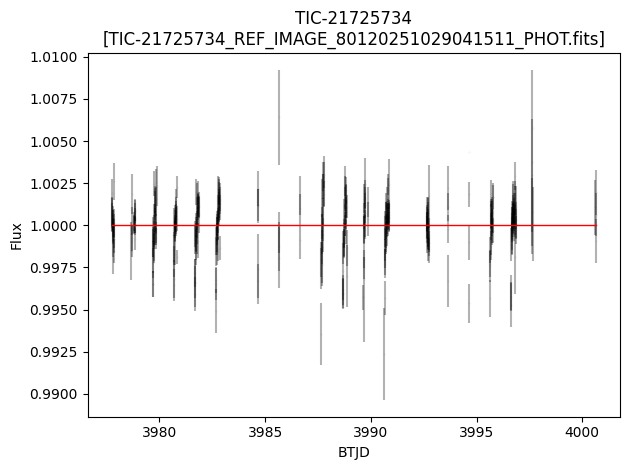

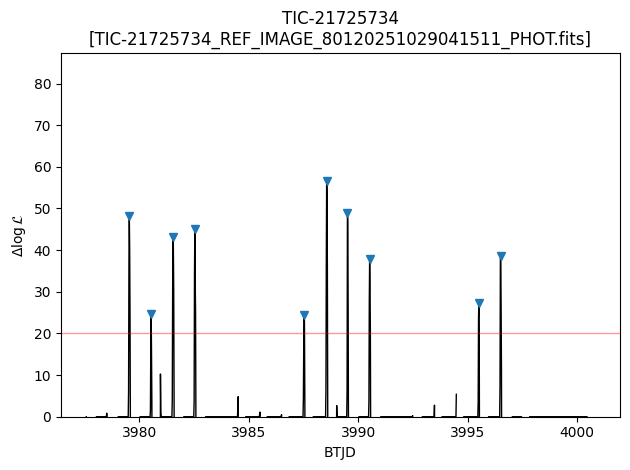

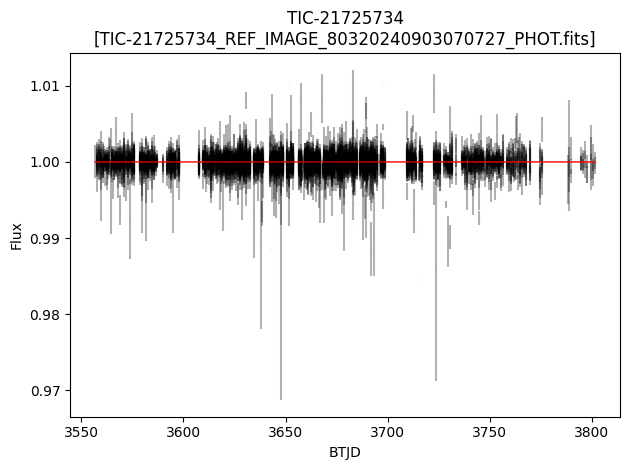

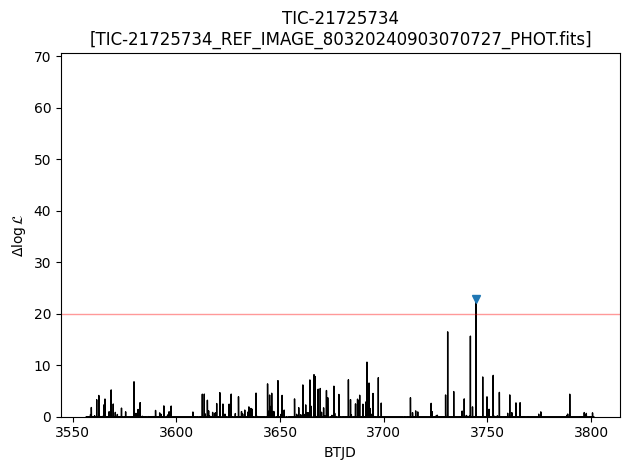

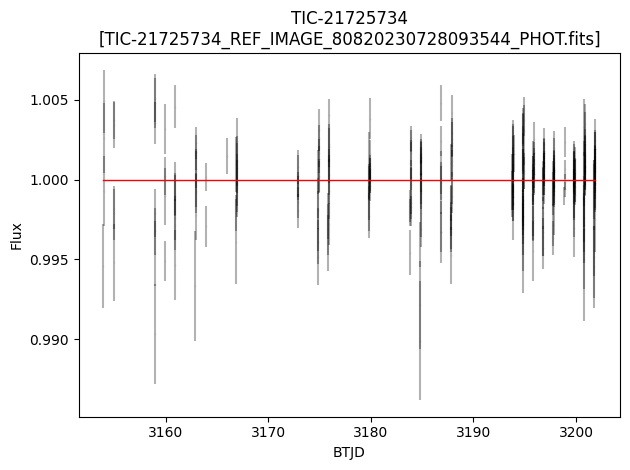

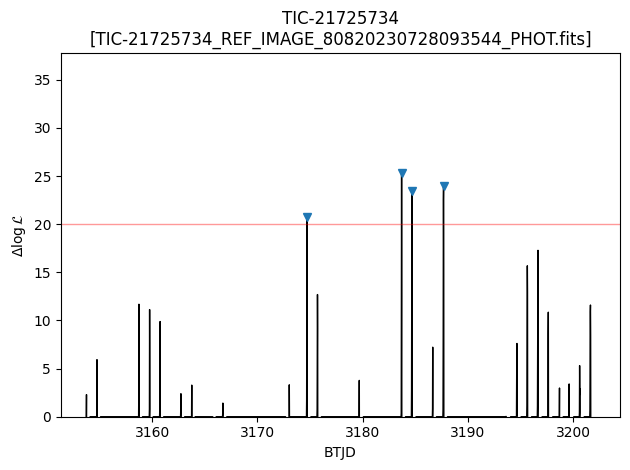

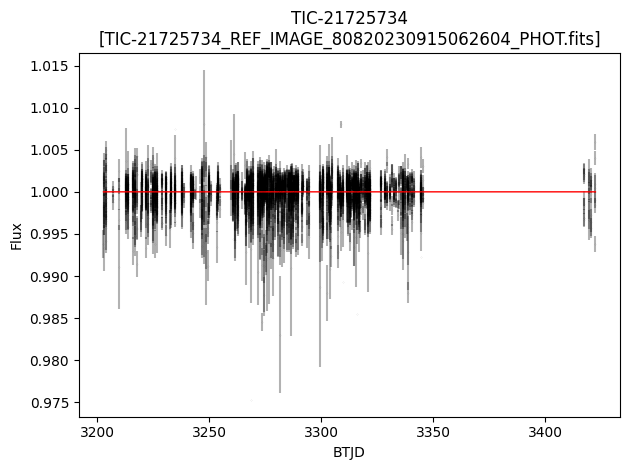

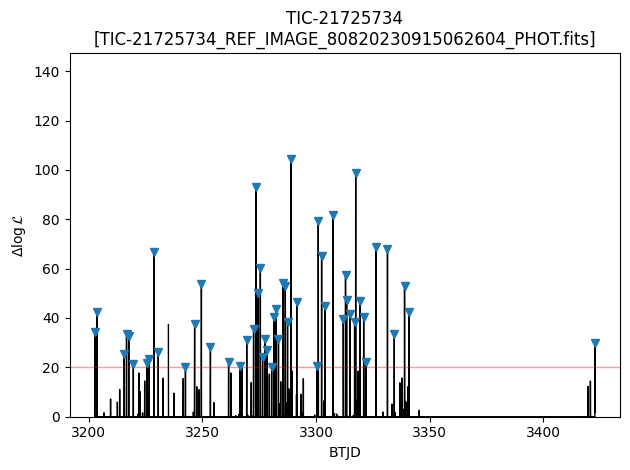

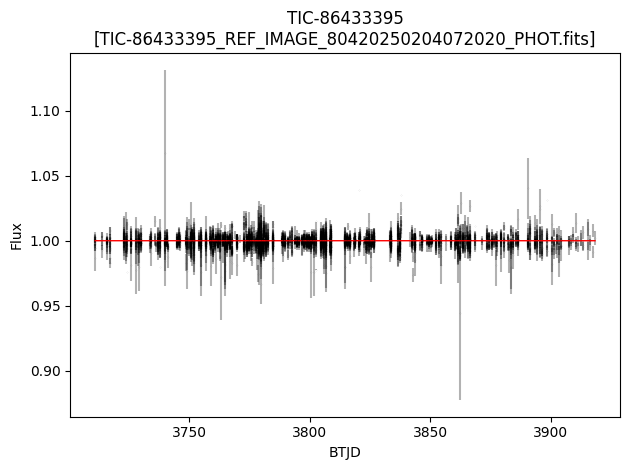

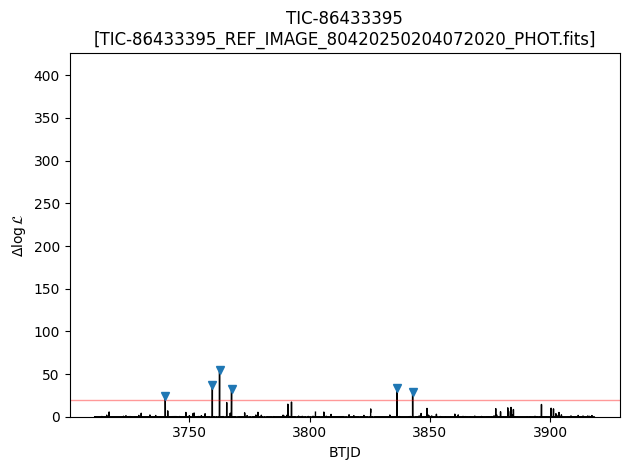

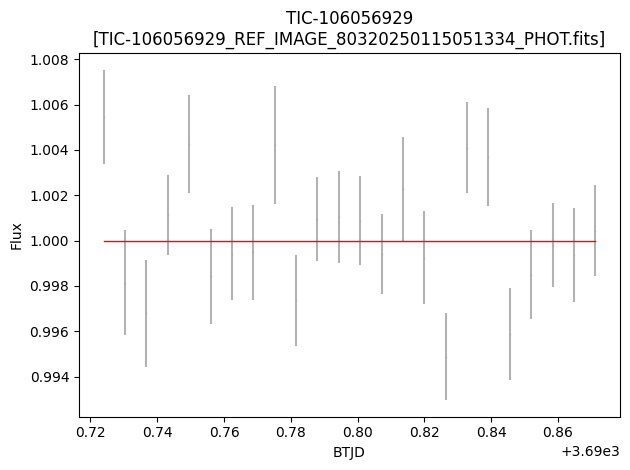

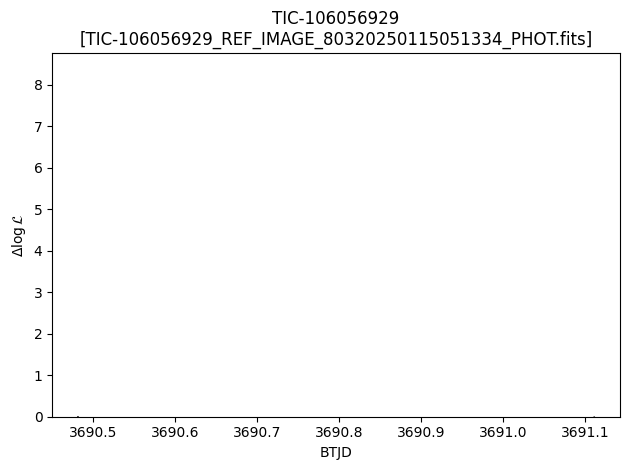

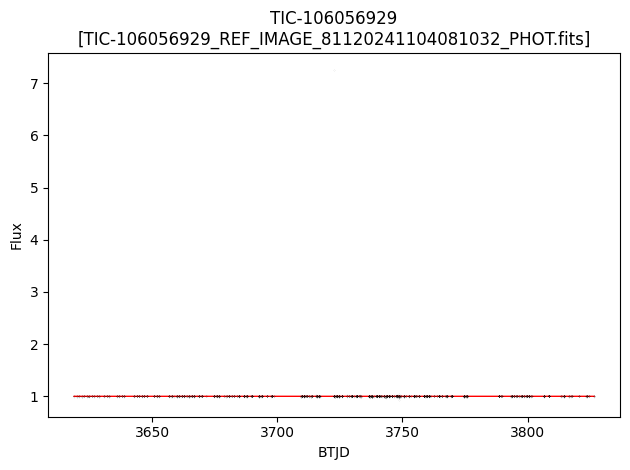

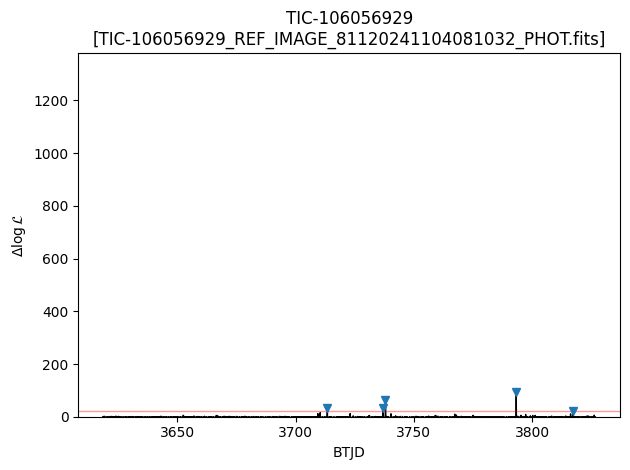

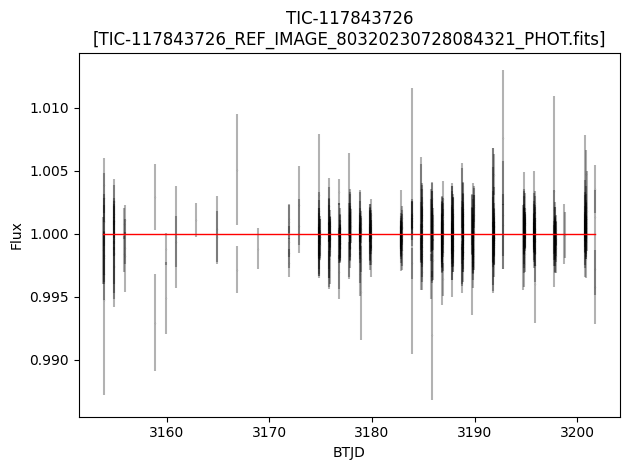

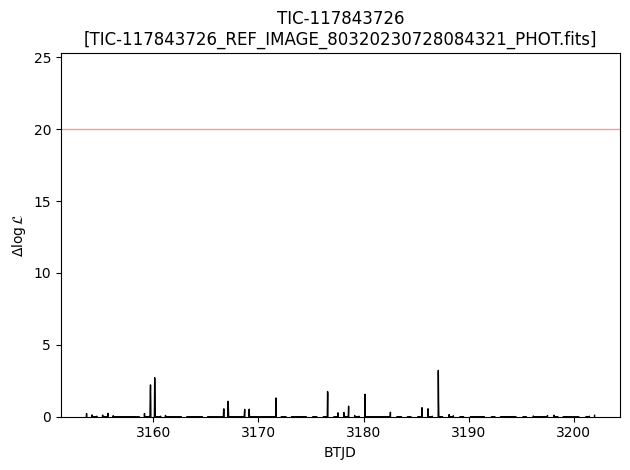

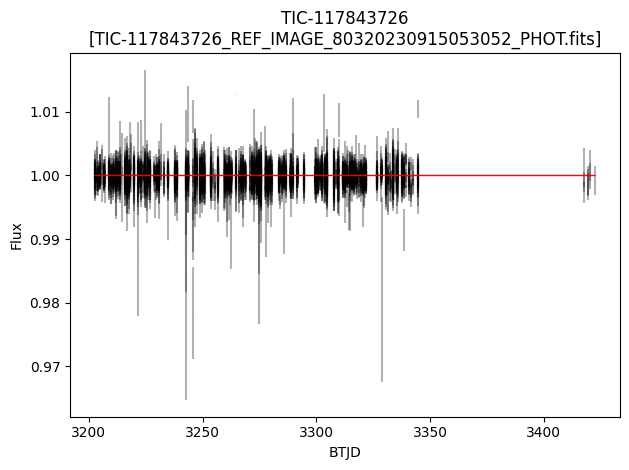

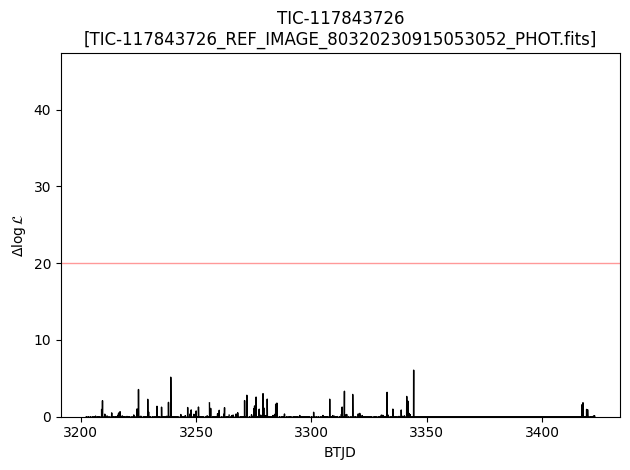

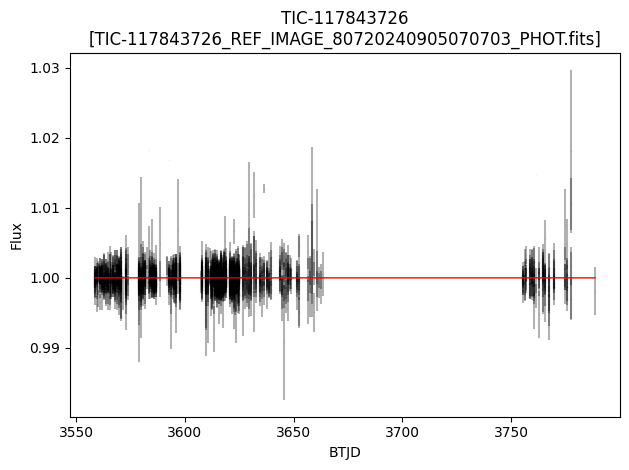

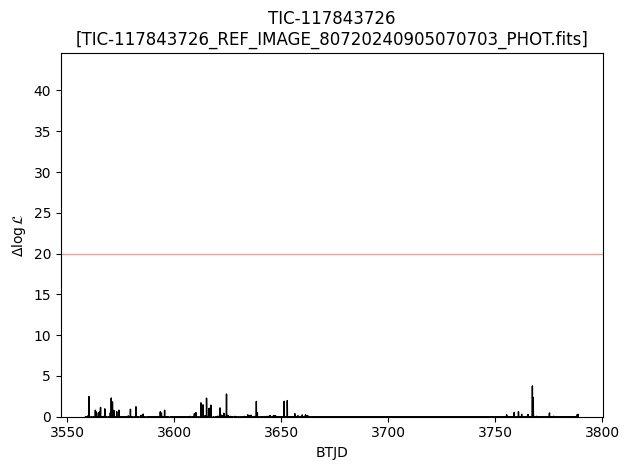

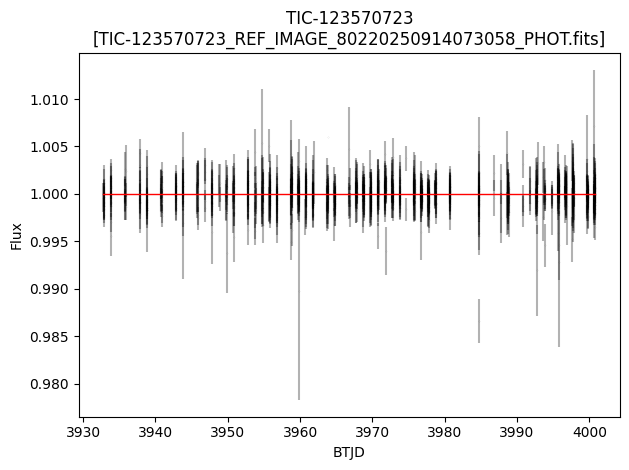

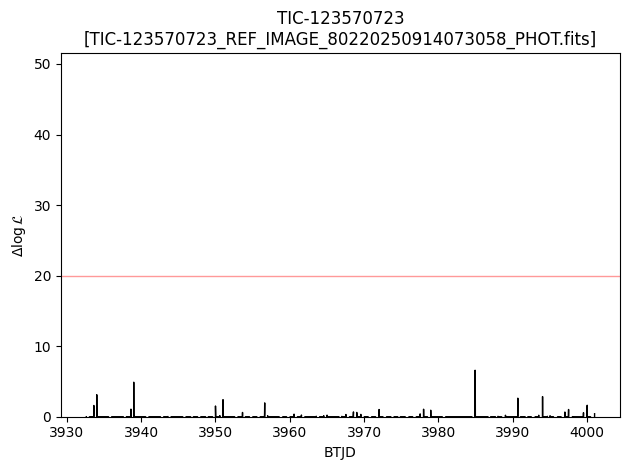

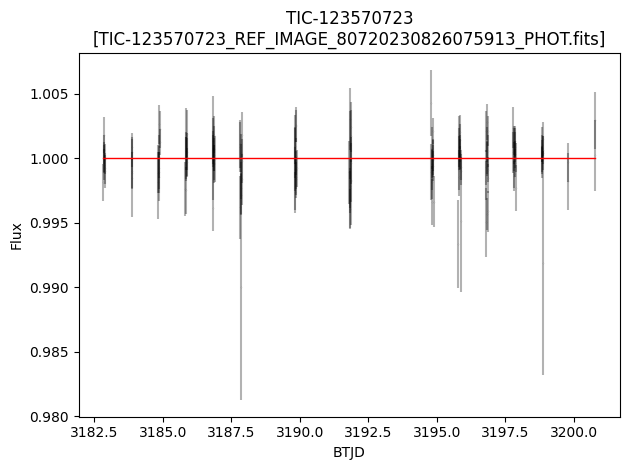

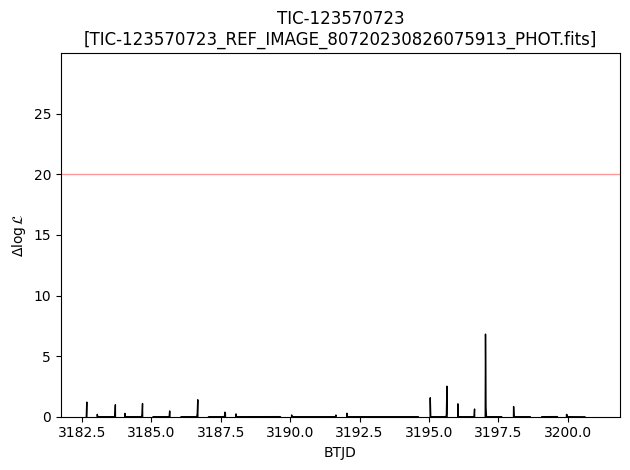

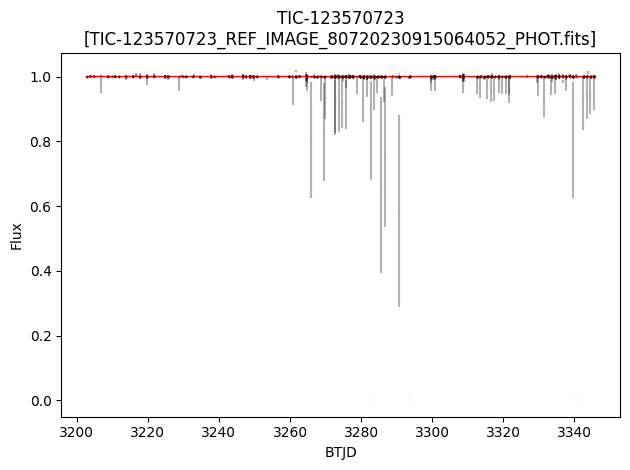

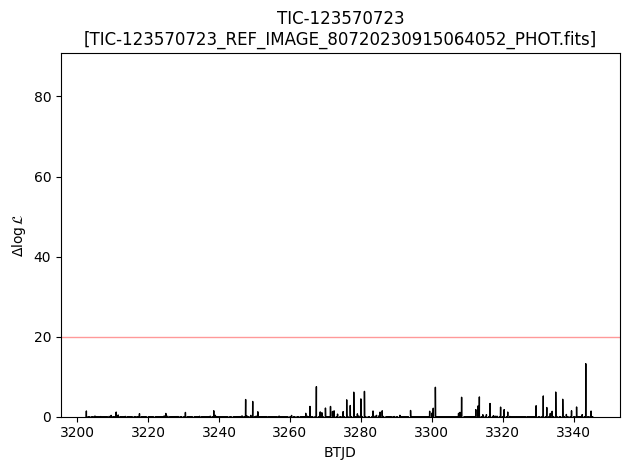

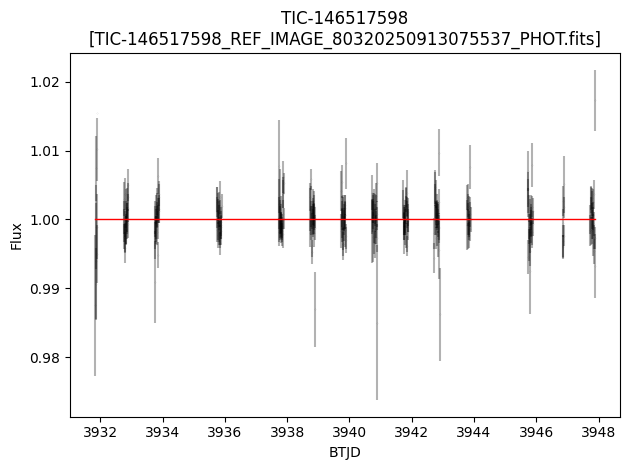

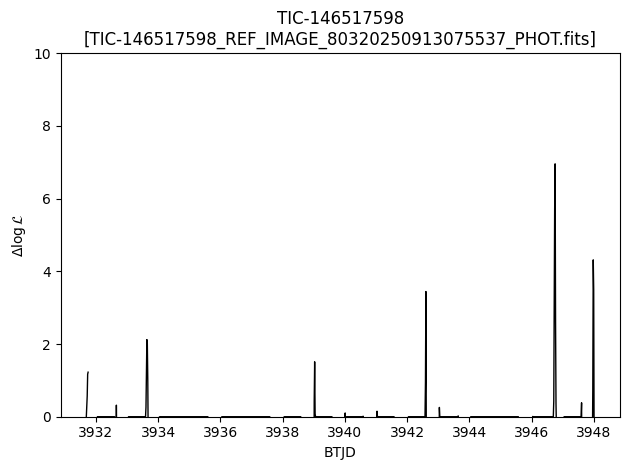

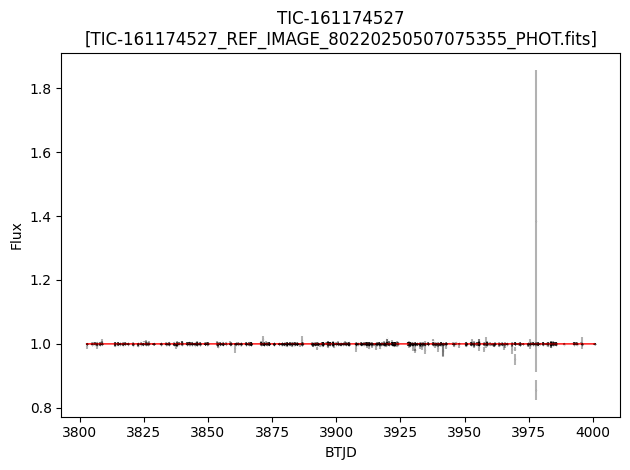

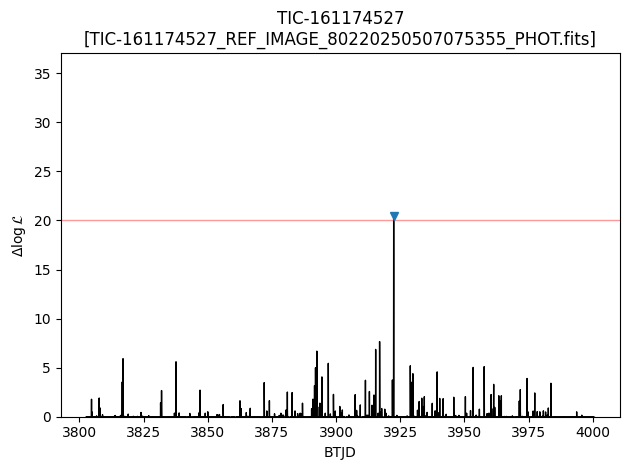

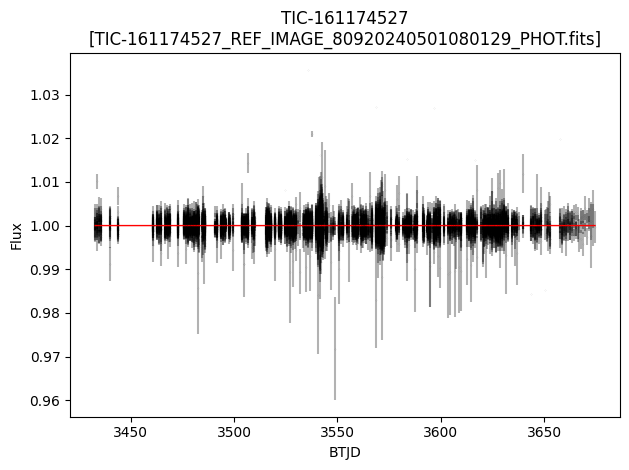

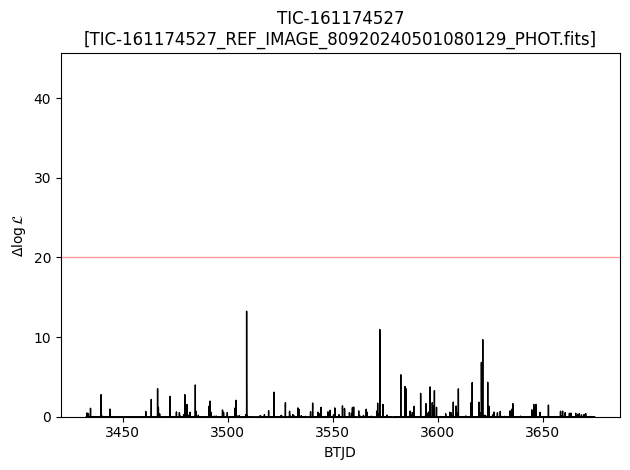

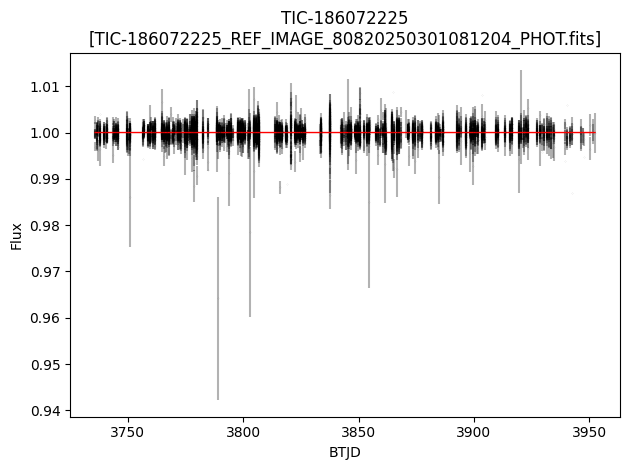

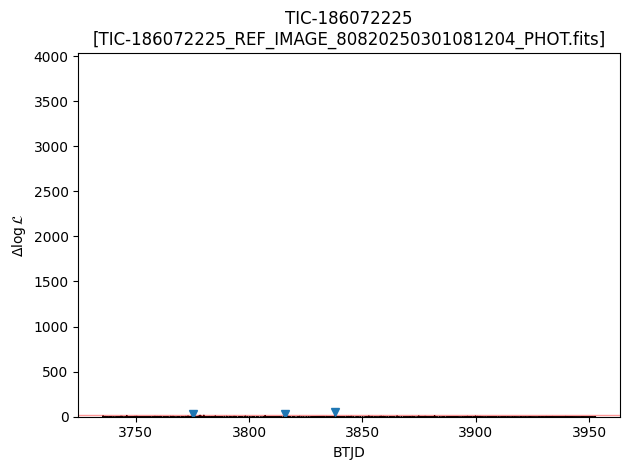

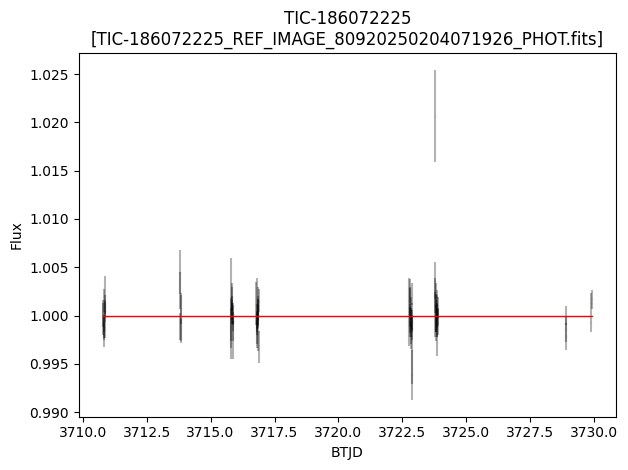

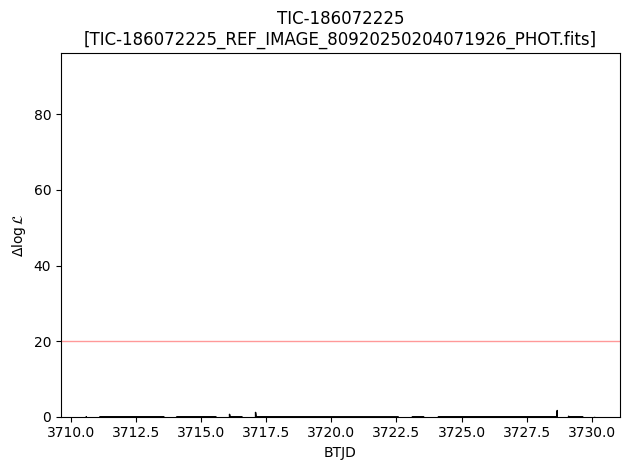

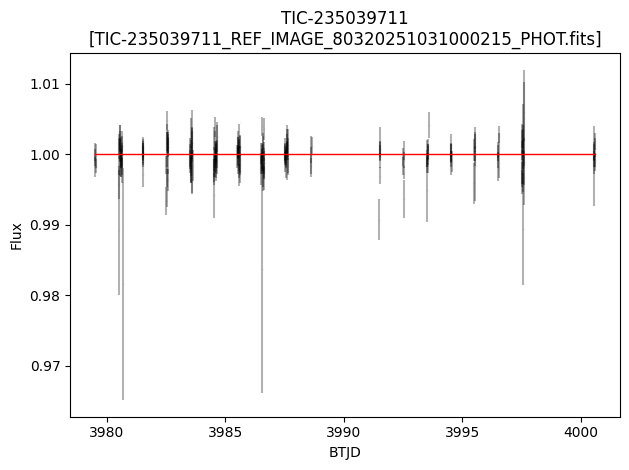

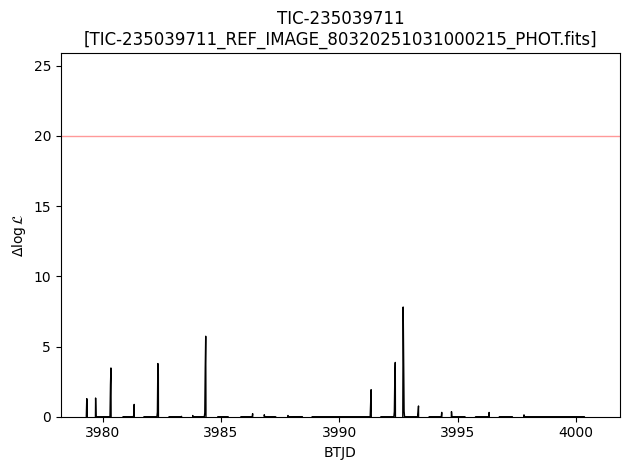

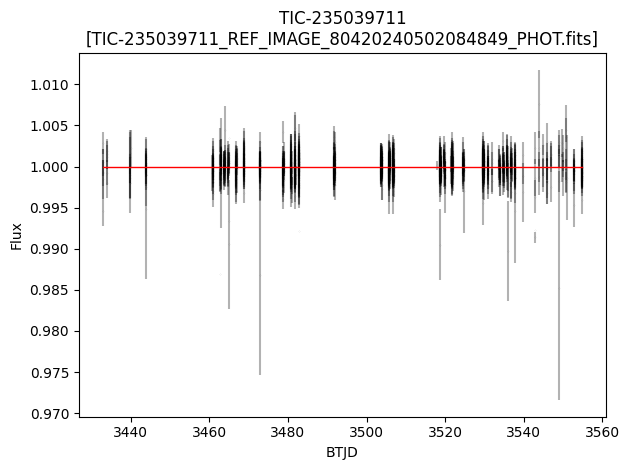

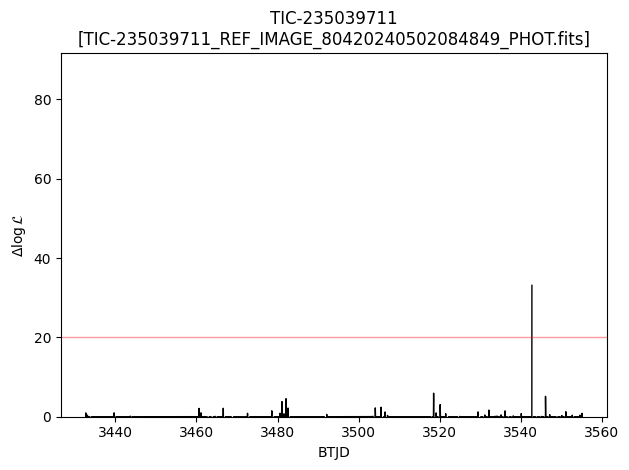

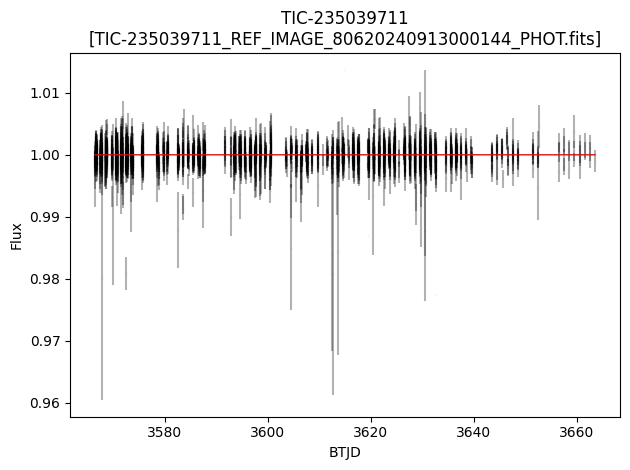

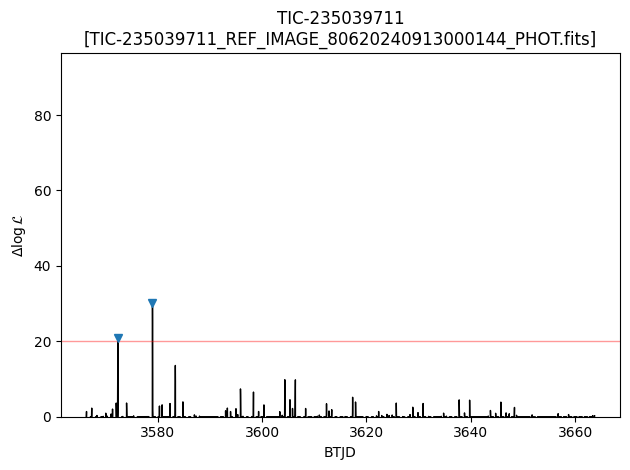

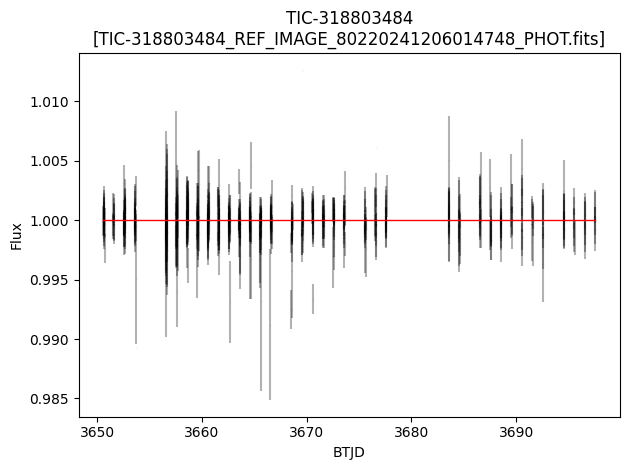

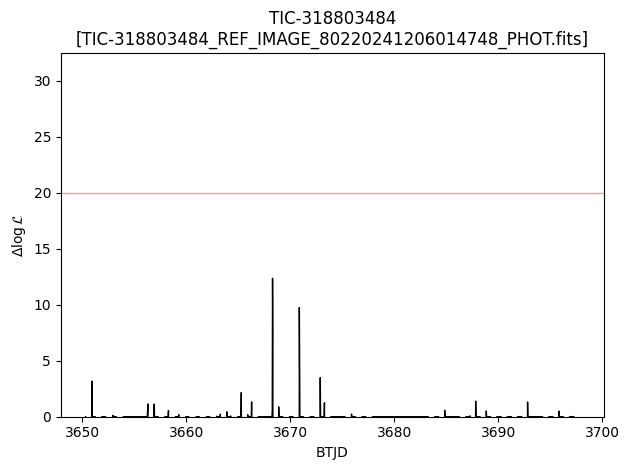

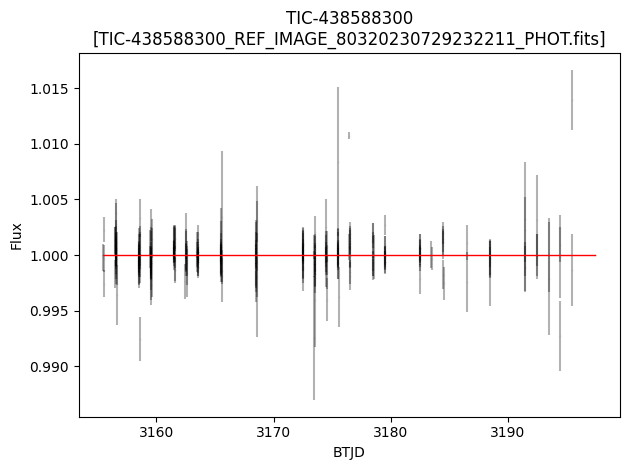

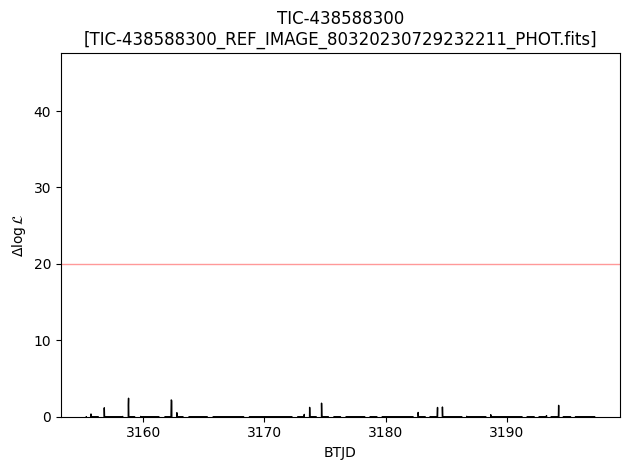

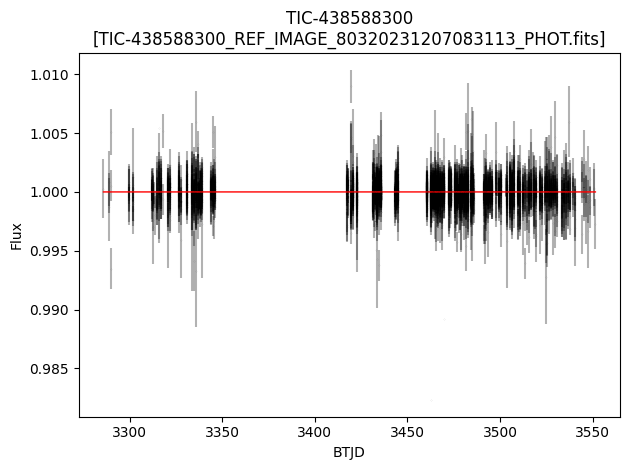

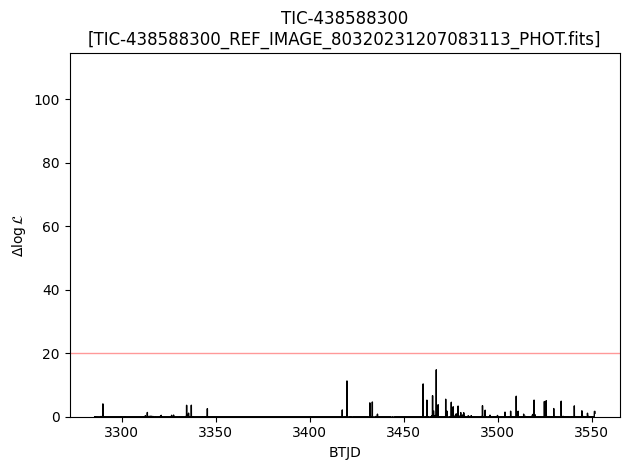

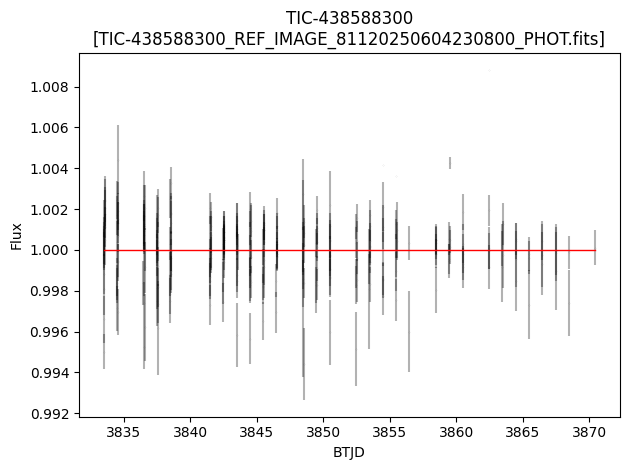

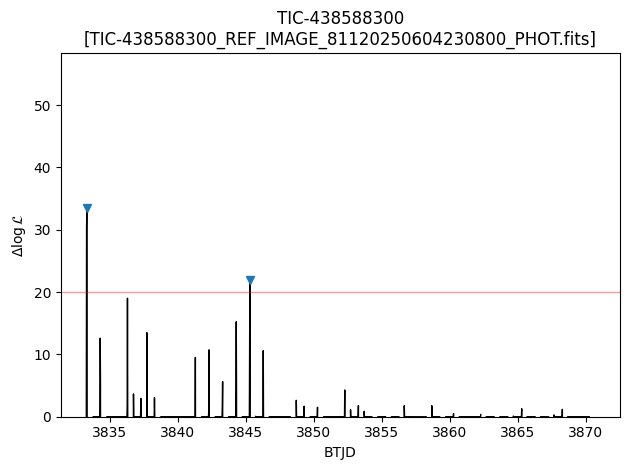

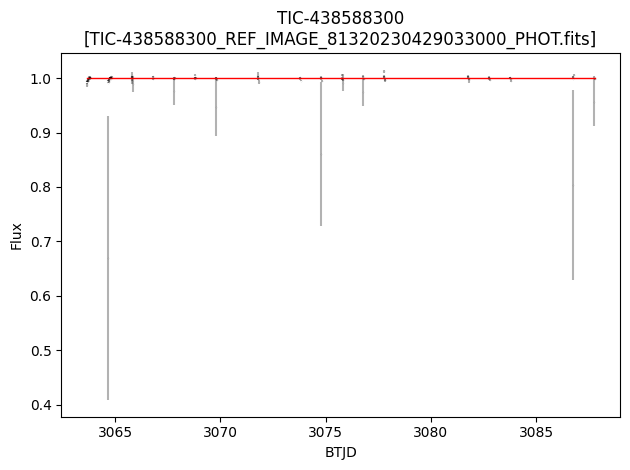

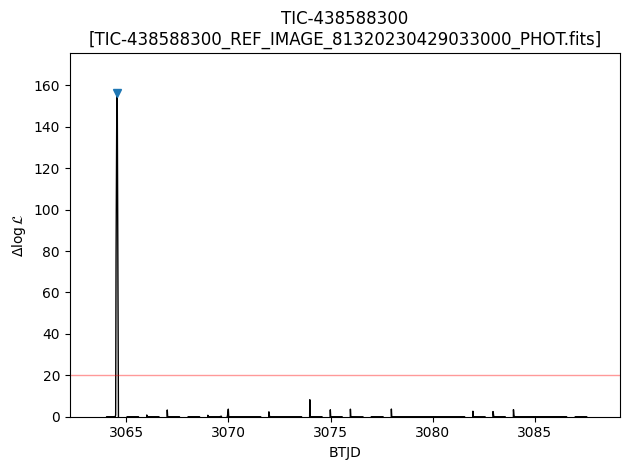

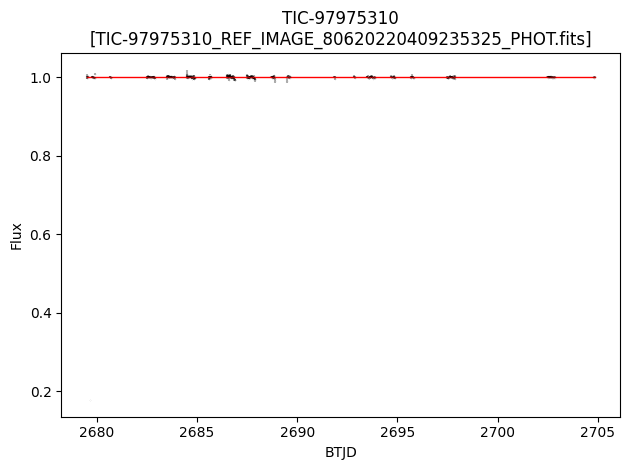

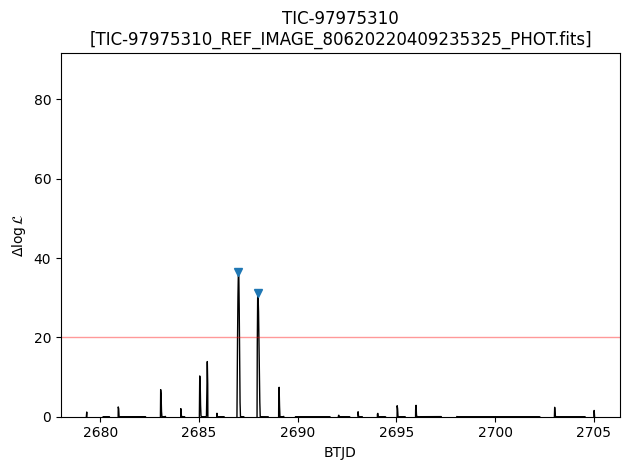

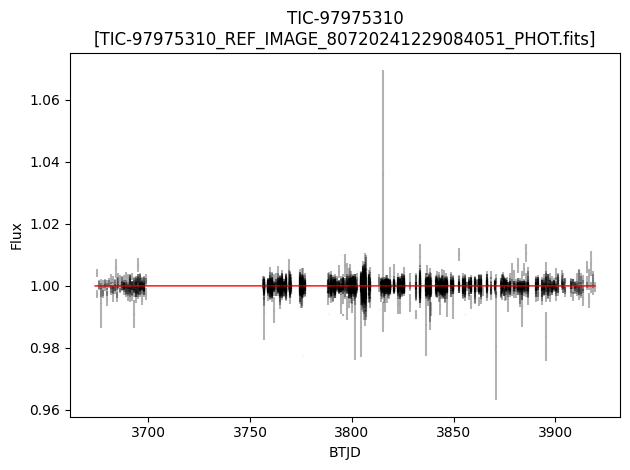

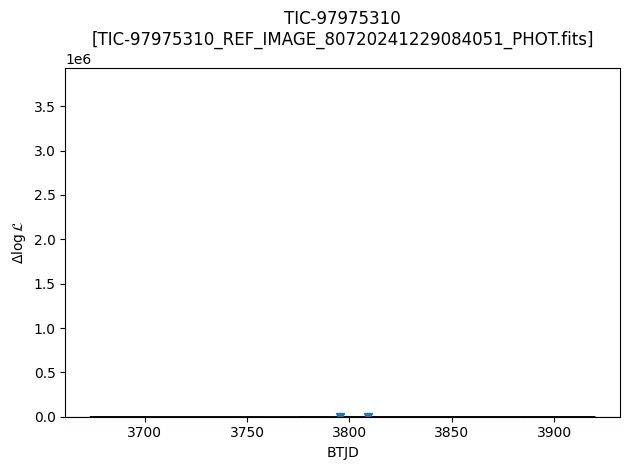

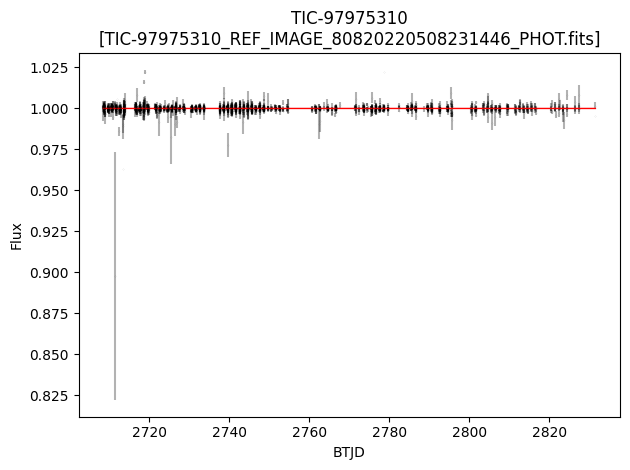

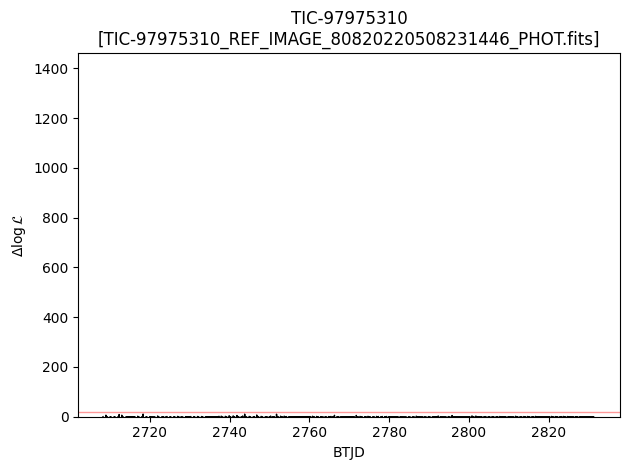

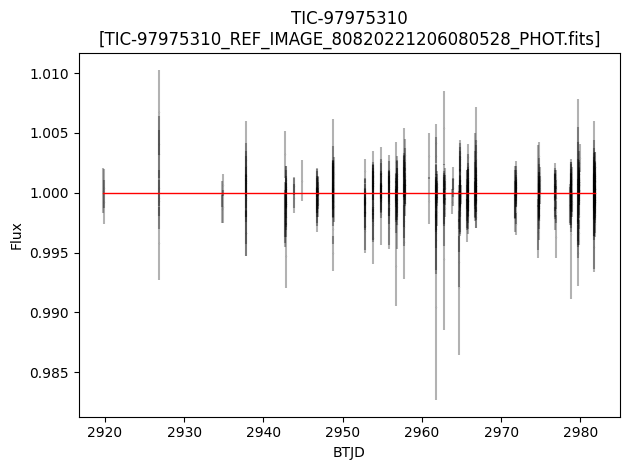

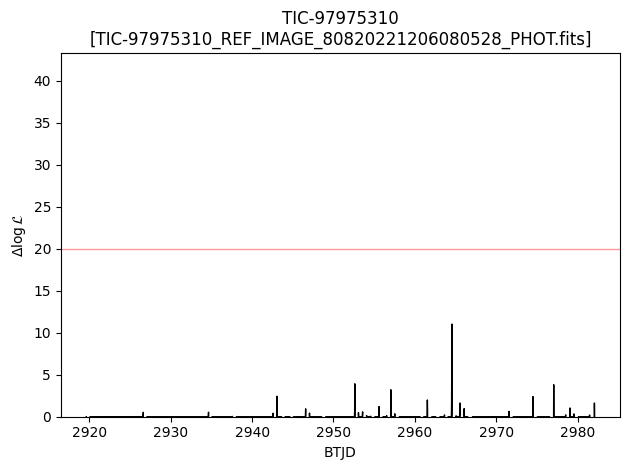

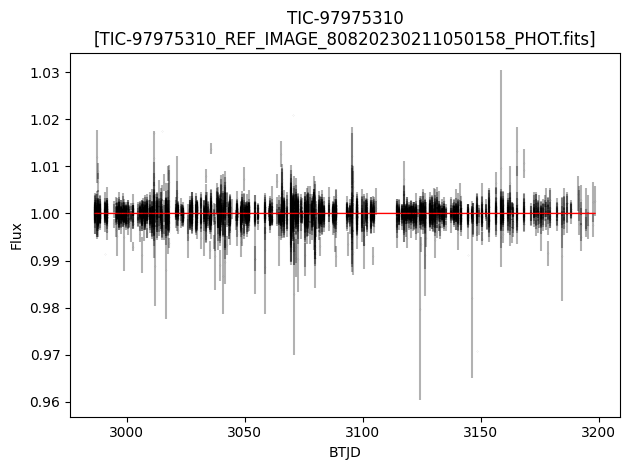

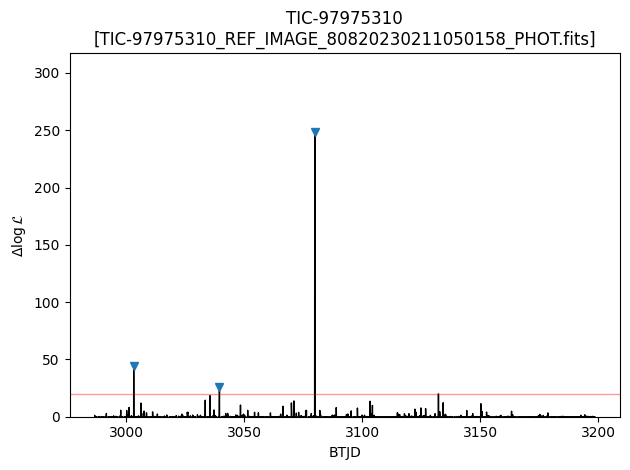

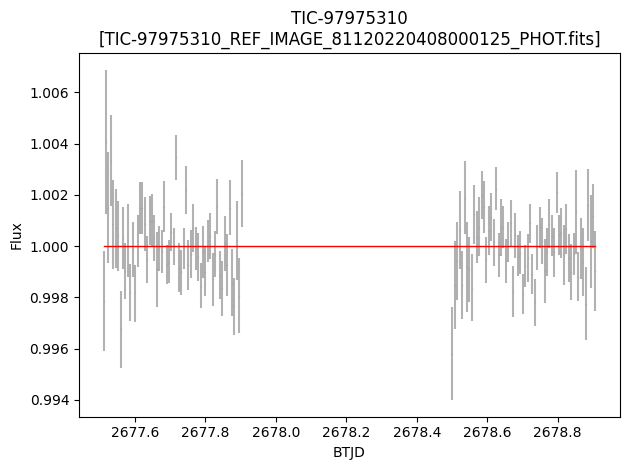

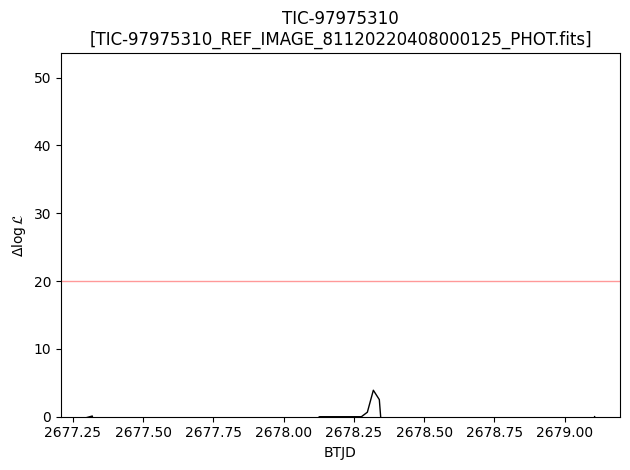

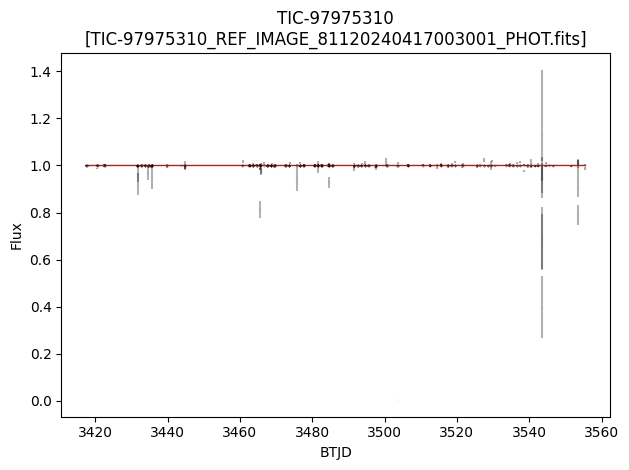

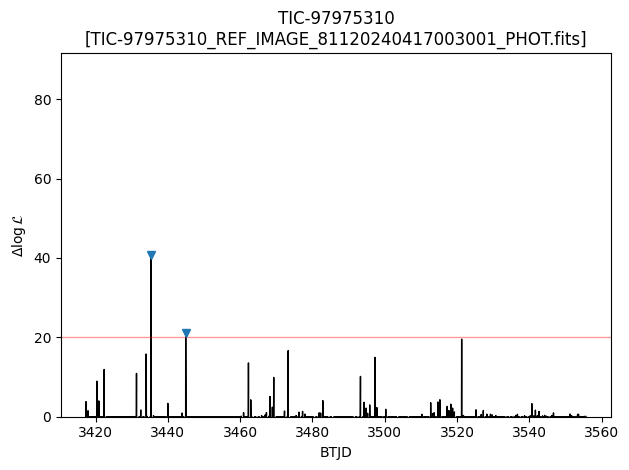

In [8]:
def tls_ngts_data(i, bin_size=0.5/24/3, median_filter_size=3, distance=20, height=50):
    files = glob.glob('/Volumes/NGTS/TIC-{:}*.fits'.format(monos['TIC ID'][i]))
    print(files)
    if len(files)==0 : return
        
        
    os.system('mkdir -p {:}'.format(monos['TIC ID'][i]))
    
    
    
    for j in range(len(files)):
        data = Table.read(files[j], hdu=fits.open(files[j])[0].header['OPTAB'])
        #data = Table.read(files[j], hdu=5)
        imagelist =  Table.read(files[j], hdu=2)
        data = hstack((imagelist, data))
        data = data[np.array(data['CLEAN'], dtype=bool)]
        
        data['FLUX_SYSREM'] = data['FLUX_SYSREM_ACTION']
        for night in np.unique(data['ACTIONID']):
            mask = data['ACTIONID']==night
            data['FLUX_ERR'][mask] = data['FLUX_ERR'][mask]/np.nanmedian(data['FLUX_SYSREM'][mask])
            data['FLUX_SYSREM'][mask] = data['FLUX_SYSREM'][mask]/np.nanmedian(data['FLUX_SYSREM'][mask])
        
        # Now bin
        t_bin, f_bin, fe_bin, c_bin = bruce.data.bin_data(data['BJD'], data['FLUX_SYSREM'], bin_size=bin_size)
        mask = (c_bin>0) #& (fe_bin>1)
        t_bin, f_bin, fe_bin, c_bin = t_bin[mask], f_bin[mask], fe_bin[mask], c_bin[mask]

        normalisation_model = bruce.data.median_filter(t_bin, f_bin, median_filter_size)
        normalisation_model = np.ones(t_bin.shape)

        # Inclination
        incl = np.arccos(monos['radius_1 (R1/a)'][i]*monos['Impact parameter'][i])
        transit_width = monos['Width [hour]'][0]/24
        
        # Now tls
        time_trial, DeltaL = bruce.template_match.template_match_lightcurve(
            t_bin,
            f_bin,
            fe_bin,
            normalisation_model,
            period=monos['FItted Period [day]'][i],
            radius_1=monos['radius_1 (R1/a)'][i],
            k=monos['k=R2/R1'][i],
            incl=incl,
            e=0.0,
            w=1.5707963267948966,
            c=0.7,
            alpha=0.4,
            cadence=0,
            noversample=10,
            light_3=0.0,
            ld_law=-2,
            accurate_tp=1,
            jitter=0.0,
            offset=0,
            time_step=None,
            time_trial=None,
        )
        
        peaks, meta = find_peaks(DeltaL, distance=distance, height=height)
        
        # Dtata 
        fig1, ax1 = plt.subplots(1,1)
        ax1.errorbar(t_bin-2457000, f_bin, yerr=fe_bin, fmt='k.', markersize=0.2, alpha = 0.3)
        ax1.plot(t_bin-2457000, normalisation_model, 'r', lw=1)
        ax1.set(xlabel='BTJD', ylabel='Flux', title = 'TIC-{:}\n[{:}]'.format(monos['TIC ID'][i], files[j].split('/')[-1]))
        plt.tight_layout()
        fig1.savefig('{:}/{:}_data.png'.format(monos['TIC ID'][i], files[j].split('/')[-1][:-5]))

        
        # Delta L
        fig2, ax2 = plt.subplots(1,1)
        ax2.plot(time_trial-2457000, DeltaL, 'k', lw=1)
        ax2.set_ylim(0,None)
        ax2.set(xlabel='BTJD', ylabel=r'$\Delta \log \mathcal{L}$', title = 'TIC-{:}\n[{:}]'.format(monos['TIC ID'][i], files[j].split('/')[-1]))
        ax2.axhline(height, c='r', lw=1, alpha=0.4)
        ax2.plot(time_trial[peaks]-2457000, DeltaL[peaks], 'v')
        plt.tight_layout()
        fig2.savefig('{:}/{:}_deltaL.png'.format(monos['TIC ID'][i], files[j].split('/')[-1][:-5]))

        
        if len(peaks)==0 : 
            print('No peaks.')
            continue 
            
        # Peaks

        ncols=3 
        nrows = int(np.ceil(len(peaks)/ncols))
        fig3, ax3 = plt.subplots(nrows,ncols, figsize = (10, 2 + 1*nrows))
        ax3 = np.atleast_1d(ax3)
        ax3 = ax3.flatten()
        
        for k in range(len(peaks)):
            action_id = imagelist['ACTIONID'][np.argmin(data['BJD']-time_trial[peaks[k]])]
            
            data_mask = (t_bin > (time_trial[peaks[k]]-transit_width)) & (t_bin < (time_trial[peaks[k]]+transit_width))
            ax3[k].errorbar(t_bin[data_mask]-time_trial[peaks[k]], f_bin[data_mask], yerr=fe_bin[data_mask], fmt='k.', markersize=0.2, alpha = 0.3)
            t_ = np.linspace(time_trial[peaks[k]]-transit_width, time_trial[peaks[k]]+transit_width, 1000)
            model = bruce.binarystar.lc(
                t_,
                t_zero = time_trial[peaks[k]],
                period=monos['FItted Period [day]'][i],
                radius_1=monos['radius_1 (R1/a)'][i],
                k=monos['k=R2/R1'][i],
                incl=incl,
                e=0.0,
                w=1.5707963267948966,
                c=0.7,
                alpha=0.4,
                cadence=0,
                noversample=10,
                light_3=0.0,
                ld_law=-2,
                accurate_tp=1,
                jitter=0.0,
                offset=0)
            ax3[k].plot(t_-time_trial[peaks[k]], np.interp(t_, t_bin,normalisation_model)*model, 'r')
            ax3[k].set(xlabel='BTJD - {:.5f}'.format(time_trial[peaks[k]]-2457000), ylabel='Flux', title='Peak {:}\nACTION {:}'.format(k+1, action_id))
        plt.tight_layout()
        fig3.savefig('{:}/{:}_deltaL_peaks.png'.format(monos['TIC ID'][i], files[j].split('/')[-1][:-5]))
        
        
        with open('{:}/TIC-{:}_peaks.dat'.format(monos['TIC ID'][i],monos['TIC ID'][i]), 'w+') as f:
            for k in range(len(peaks)):
                f.write('{:},{:},{:}\n'.format(k+1, time_trial[peaks[k]], DeltaL[peaks[k]]))
                
        plt.close()
        gc.collect()

        
%matplotlib inline 
for i in range(len(monos)) : tls_ngts_data(i, height=20)
    
#tls_ngts_data(np.argwhere(monos['TIC ID']==21725734)[0][0], height=50)